# Figure 3: density overlap between the HLNA and the Southern Ocean channel

Area-weighted 5th and 95th percentiles of late-winter surface sigma_1 (February-April in the HLNA, 50-65N;
August-October in the Southern Ocean channel, 75-55S, Atlantic sector), smoothed with a 15-year Butterworth filter.
The AMOC can recover only when the two ranges overlap.

Input: `FMAASOmean_sigma1_cells_{8x,4x,2x}_natl20-80N_so75-50S.nc`

In [1]:
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import common

matplotlib.rc('font', size=14)

In [2]:
series_by_run = {run: common.density_ranges(run, common.HLNA_LAT) for run in ('8x', '4x', '2x')}

for run, s in series_by_run.items():
    spun_up = s['years'] >= 200
    print(f"{run}: HLNA p95 above S.O. p5 in {100 * (s['natl_hi'][spun_up] > s['so_lo'][spun_up]).mean():.0f}% of years from year 200")

# When the overlap begins in 8xCO2: the year after the last year without overlap
s8 = series_by_run['8x']
print('8x overlap is continuous from year', s8['years'][(s8['years'] >= 200) & (s8['natl_hi'] <= s8['so_lo'])].max() + 1)

8x: HLNA p95 above S.O. p5 in 55% of years from year 200
4x: HLNA p95 above S.O. p5 in 100% of years from year 200
2x: HLNA p95 above S.O. p5 in 100% of years from year 200
8x overlap is continuous from year 2425


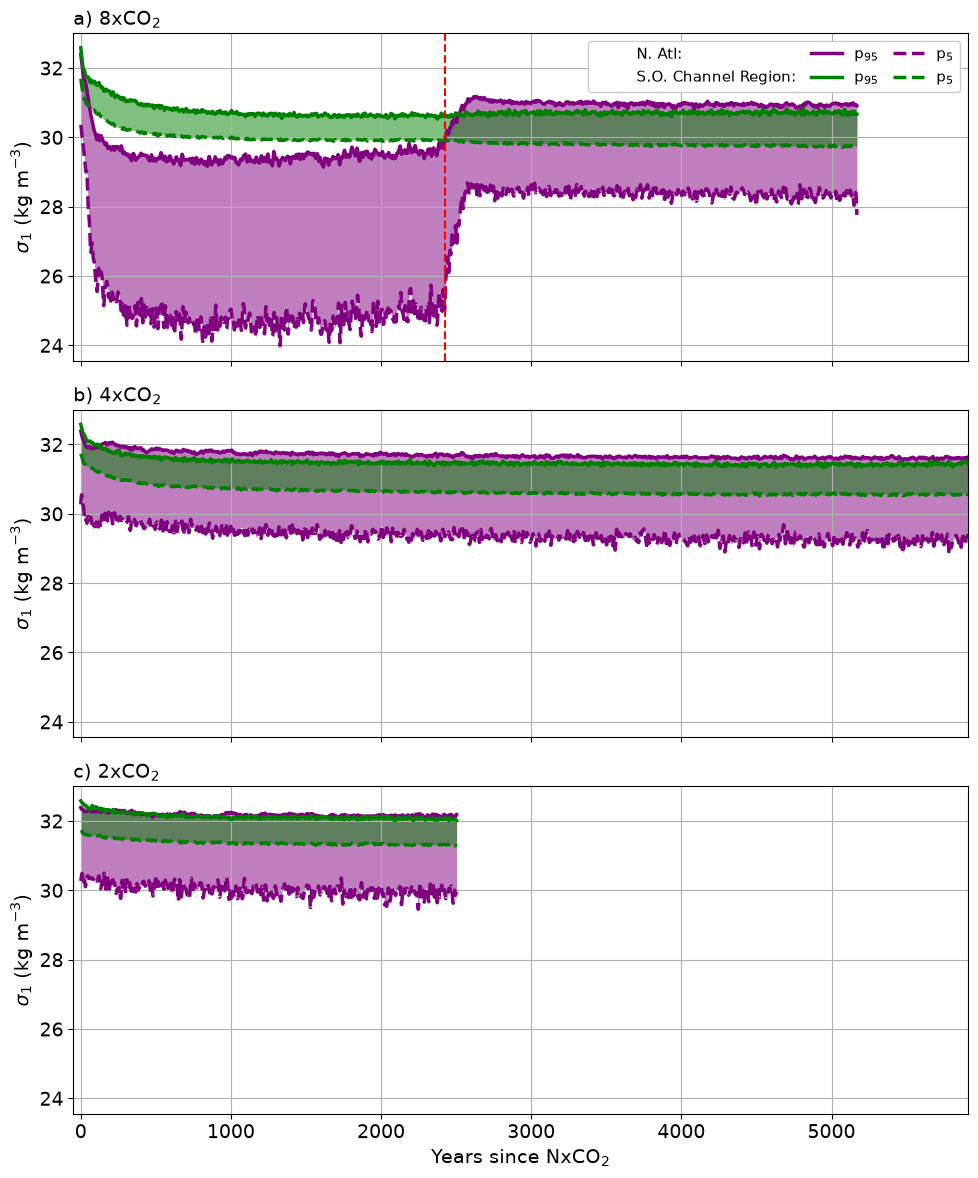

In [3]:
def plot_density_bands(ax, series, event_year=None, natl_header='N. Atl:', linewidth=2.5):
    """Draw a run's N. Atlantic and Southern Ocean density ranges on ax: p95 solid, p5 dashed, range shaded."""
    years = series['years']
    natl_color, so_color = 'purple', 'green'
    hi_label, lo_label = f'p$_{{{common.PCT_HI}}}$', f'p$_{{{common.PCT_LO}}}$'
    # Invisible handles act as the two row headers of the legend
    ax.plot([], [], linestyle='None', color='None', label=natl_header)
    ax.plot([], [], linestyle='None', color='None', label='S.O. Channel Region:')
    ax.plot(years, series['natl_hi'], color=natl_color, linewidth=linewidth, label=hi_label)
    ax.plot(years, series['so_hi'], color=so_color, linewidth=linewidth, label=hi_label)
    ax.plot(years, series['natl_lo'], color=natl_color, linestyle='--', linewidth=linewidth, label=lo_label)
    ax.plot(years, series['so_lo'], color=so_color, linestyle='--', linewidth=linewidth, label=lo_label)
    ax.fill_between(years, series['natl_hi'], series['natl_lo'], alpha=0.5, color=natl_color, linewidth=0)
    ax.fill_between(years, series['so_hi'], series['so_lo'], alpha=0.5, color=so_color, linewidth=0)
    if event_year is not None:
        ax.axvline(event_year, color='red', linestyle='--', linewidth=1.5)
    ax.grid()


panels = [('8x', 'a)', common.RECOVERY_YEAR), ('4x', 'b)', None), ('2x', 'c)', None)]
fig, axes = plt.subplots(len(panels), 1, figsize=(10, 12), sharey=True, sharex=True)
for ax, (run, panel_label, event_year) in zip(axes, panels):
    plot_density_bands(ax, series_by_run[run], event_year)
    ax.set_title(f'{panel_label} {run}CO$_2$', loc='left', fontsize=14)
    ax.set_ylabel('$\\sigma_1$ (kg m$^{-3}$)')

# One year scale in all panels; the longest record (4x) sets the range
axes[0].set_xlim(-common.X_START_PAD, max(s['years'][-1] for s in series_by_run.values()))
axes[-1].set_xlabel('Years since NxCO$_2$')
# Shared y range: the bottom comes from autoscaling over all three runs, the top is fixed
axes[0].set_ylim(axes[0].get_ylim()[0], 33)
# The lines mean the same in every panel, so one legend is enough
axes[0].legend(ncol=3, fontsize=11, loc='upper right', columnspacing=1.0).get_frame().set_alpha(1)

fig.tight_layout()
for extension in ('png', 'pdf'):
    fig.savefig(common.figure_path(f'fig03_density_overlap.{extension}'), dpi=300, bbox_inches='tight')
plt.show()